# Day 5(M1 Day05) 실습 — 품질 게이트·피드백 루프·M1 캡스톤

**목표**: 코드 검사기와 루브릭 검증자로 품질 게이트를 만들고, 미달이면 피드백을 들고 다시 쓰는 루프를 붙여 M1 리서치 팀을 완성한다.
## 오늘의 전체 그림

**오늘의 질문**: 결과가 기준에 못 미치면 누가 판정하고, 무엇을 들고 다시 쓰게 하나? 언제 멈추나?

```text
[Part 1 만든다]   스타일 검사기 check_style(코드) · 루브릭 검증자 evaluate(LLM) · write_draft · run_loop
      │           → 통과 판정은 코드가, 미달이면 피드백을 들고 다시 쓴다 (기준·한도·최고 버전)
      ▼
[Part 2 흔든다]   모르고 다시 vs 알고 다시 · 기준 조절 · 채점 재현성 · 1차 실패율
      │           → (확장) 오류를 심은 초안으로 검증자 자체를 시험한다
      ▼
[Part 3 조립한다] M1 캡스톤: 병렬 분석(Day 4) → 통합 → 게이트 → (미달 시) 통합 재시도
                  → (확장) Day 4에서 환각이 나왔던 자료로 게이트를 시험한다
```

| Part | 블록 | 답하는 질문 | 다음 Part로 넘기는 것 |
| --- | --- | --- | --- |
| Part 1 | 따라 하기 | 품질은 누가 재고, 미달이면 어떻게 다시 쓰나? | `check_style` · `evaluate` · `total` · `is_better` · 기준·한도 |
| Part 2 | 바꿔 보기 | 재시도는 무엇을 들고 해야 하고, 채점은 믿을 만한가? | 피드백을 들고 다시 쓰기 · 기준(threshold)의 의미 |
| Part 3 | 미니 프로젝트 | M1에서 만든 부품을 한 팀으로 묶으면? | 검증 루프를 갖춘 리서치 팀 → M2에서 서비스로 |

> 💡 세 Part는 코드를 이어 쓴다. Part 3은 Part 1의 검사기·검증자·`is_better`와 Day 4의 분석가·통합자를 함께 쓴다.

> 💡 **2과목 Day 16 Self-Reflection과 무엇이 다른가**: 그때는 같은 모델이 스스로 비평했다. 오늘은 판정을 **다른 역할로 분리**한다 — 잴 수 있는 것은 코드가, 못 재는 것은 별도 검증자가 채점하고, 통과 여부는 코드가 정한다 (Day 1 원칙).

## 0. 환경 준비

> 💡 Part 1·2의 루프는 함수(`run_loop`)로, Part 3의 캡스톤은 LangGraph로 짠다. 같은 "검사 → 미달이면 다시"를 반복문으로 쓰느냐, 조건 엣지로 되돌아가느냐의 차이다.

과제: 달빛 도서관 자료로 "잠재 투자자용 소개 글"을 쓴다.

In [1]:
import os

# 추적 끄기: 2과목 Day17에서 .env의 LANGSMITH_TRACING을 켰다면 오늘 호출이 전부 전송된다
os.environ["LANGSMITH_TRACING"] = "false"
os.environ["LANGCHAIN_TRACING_V2"] = "false"

import operator
import statistics
from typing import Annotated

from dotenv import load_dotenv
from langchain_openai import ChatOpenAI
from langgraph.graph import END, START, StateGraph
from langgraph.types import Send
from pydantic import BaseModel, Field
from typing_extensions import TypedDict

load_dotenv()

llm = ChatOpenAI(model="gpt-4o-mini", temperature=0.9)  # 작성자·분석가
llm_strict = ChatOpenAI(model="gpt-4o-mini", temperature=0)  # 검증자·통합자

SOURCE = """[내부 소개 자료] 달빛 도서관
달빛 도서관은 밤 10시부터 새벽 2시까지 여는 무인 야간 도서관이다.
서울 마포구에 1호점이 있으며, 좌석은 총 48석이다.
입장은 월 구독제이며, 구독료는 월 19,900원이다.
사서 대신 안내 로봇 '루나'가 책 추천과 반납을 돕는다.
조용한 환경을 위해 통화와 취식은 금지된다.
회원의 62%가 20~30대 직장인이다.
2026년 12월에 부산 2호점이 문을 열 예정이다."""

REQUEST = "잠재 투자자에게 보낼 소개 글. 서비스 개요·고객·수익 모델·확장 계획을 모두 담을 것. 4~6문장."

print("준비 완료:", llm.model_name)

준비 완료: gpt-4o-mini


## Part 1. 따라 하기 — 품질 게이트와 피드백 루프

**전체 그림 1/3**: 코드 검사기와 LLM 검증자로 게이트를 만들고, 미달이면 피드백을 들고 다시 쓰는 루프를 만든다 → Part 2·3이 이 부품을 그대로 쓴다.

```text
작성자 → [게이트: 스타일 검사(코드) + 루브릭 채점(검증자)] → 통과? ─ 예 → 끝
                                                          └ 아니오 → 피드백을 들고 작성자에게 (최대 N번)
```

### 1-1. 스타일 검사기 — 코드로 잴 수 있는 품질

회사 스타일 가이드: 과장 표현 금지 + 핵심 수치 인용 필수.
이 규칙은 **게이트가 가지고 있다** — 작성자는 처음엔 모르고, 걸리면 피드백으로 배운다.

In [72]:
SOURCE

"[내부 소개 자료] 달빛 도서관\n달빛 도서관은 밤 10시부터 새벽 2시까지 여는 무인 야간 도서관이다.\n서울 마포구에 1호점이 있으며, 좌석은 총 48석이다.\n입장은 월 구독제이며, 구독료는 월 19,900원이다.\n사서 대신 안내 로봇 '루나'가 책 추천과 반납을 돕는다.\n조용한 환경을 위해 통화와 취식은 금지된다.\n회원의 62%가 20~30대 직장인이다.\n2026년 12월에 부산 2호점이 문을 열 예정이다."

In [73]:
BANNED = ["혁신", "최고", "완벽", "획기적", "세계적", "압도적"]
REQUIRED = ["19,900원", "62%"]


def check_style(draft):
    """스타일 가이드 검사기 (코드, 결정적)"""
    violations = []
    for w in BANNED:
        # TODO: 금지 단어 w가 draft에 있으면 violations에 f'과장 표현 "{w}" 사용 금지'를 추가하세요
        if w in draft:
            violations.append(f'과장 표현 "{w}" 사용 금지')
    for r in REQUIRED:
        # TODO: 필수 수치 r이 draft에 없으면 violations에 f'필수 수치 "{r}" 누락'을 추가하세요
        if r not in draft:
            violations.append(f'필수 수치 "{r}" 누락')
    return violations

In [53]:
print(check_style("혁신적인 최고의 도서관입니다."))
print(check_style("구독료는 월 19,900원이며 회원의 62%가 직장인입니다."))

['과장 표현 "혁신" 사용 금지', '과장 표현 "최고" 사용 금지', '필수 수치 "19,900원" 누락', '필수 수치 "62%" 누락']
[]


### 1-2. 루브릭 검증자 — 코드로 못 재는 품질

사실 충실·완성도·명료성은 LLM이 채점하되, **감점 기준을 항목 설명에 적는다**.

> ⚠️ 감점 기준이 없으면 검증자가 무엇이든 15/15를 준다 — 원문에 없는 "혁신"이 든 초안에도 만점을 줬다 (사전 검증).

In [74]:
class Evaluation(BaseModel):
    """검증자의 출력 계약 — 감점 기준을 항목 설명에 적는다"""

    # TODO: 감점 기준을 설명에 적으세요 ("원문에 없는 내용이 하나라도 있으면 3 이하" 등)
    faithfulness: int = Field(description="사실 충실성 1~5. 원문에 없는 내용이 하나라도 있으면 3 이하")
    completeness: int = Field(description="완성도 1~5. 요청 요소(개요·고객·수익·확장) 중 하나라도 미흡하면 3 이하.")
    clarity: int = Field(description="명료성 1~5. 문장이 늘어지거나 반복되면 감점.")
    feedback: str = Field(description="점수를 올리기 위한 구체적 개선 지시 2~3개. 한국어.")

# 검증자
def evaluate(request, source, draft):
    prompt = f"""당신은 사실 검증기입니다. 사실 여부는 반드시 SOURCE만 근거로 판단하세요.
REQUEST나 사전 지식으로 SOURCE에 없는 내용을 보완하지 마세요.


DRAFT를 검증 가능한 사실 주장 단위로 나누고, 각 주장에 아래 중 하나를 표시하세요.
- SUPPORTED: SOURCE가 그 주장을 뒷받침함
- CONTRADICTED: SOURCE의 내용과 다름
- NOT_STATED: SOURCE에서 확인할 수 없음


숫자, 금액, 비율, 날짜, 시간, 장소는 정확히 대조하세요.
예를 들어 SOURCE가 19,900원인데 DRAFT가 29,900원이라고 쓰면 CONTRADICTED입니다.
SOURCE에 주말 운영 시간이 없는데 DRAFT가 주말 24시간 운영이라고 쓰면 NOT_STATED입니다.
문맥상 그럴듯하다는 이유로 SUPPORTED로 판정하지 마세요.


faithfulness 점수:
- 모든 주장이 SUPPORTED이면 5
- CONTRADICTED 주장이 하나라도 있으면 1
- CONTRADICTED는 없지만 NOT_STATED 주장이 하나라도 있으면 2


각 판정에 근거가 된 SOURCE의 문구를 인용하세요.
결과는 JSON으로만 반환하세요.


[요청]
{request}


[원문]
{source}


[초안]
{draft}"""

    # TODO: 판정 역할용 모델(llm_strict)에 Evaluation 계약을 걸어(with_structured_output) prompt를 호출하고 결과를 반환하세요
    return llm_strict.with_structured_output(Evaluation).invoke(prompt)

def total(ev):
    # TODO: 세 항목(faithfulness · completeness · clarity) 점수의 합을 반환하세요
    return ev.faithfulness + ev.completeness + ev.clarity


print("검증자 준비 완료")

검증자 준비 완료


### 1-3. 작성자 — 피드백 반영형

`feedback`이 있으면 프롬프트에 "반드시 반영"으로 붙는다. 초안 1회를 만들어 게이트에 넣어 본다.

In [75]:
def write_draft(request, source, feedback=None):
    """작성자: 피드백이 있으면 반드시 반영한다."""
    prompt = f"당신은 작성자입니다. 원문의 사실만 사용해 요청에 맞는 글을 쓰세요. 글만 출력하세요.\n\n[요청]\n{request}\n\n[원문]\n{source}"
    # TODO: feedback이 있으면 prompt 끝에 "[검증 게이트의 개선 지시 — 반드시 모두 반영]" 제목과 feedback을 붙이세요
    #       ("반드시 모두 반영"이라고 써야 작성자가 지시를 흘려듣지 않는다)
    if feedback:
            prompt += f"\n\n[검증 게이트의 개선 지시 — 반드시 모두 반영]\n{feedback}"
    # TODO: 생성 역할용 모델(llm)로 prompt를 호출하고, 응답 내용(content)의 앞뒤 공백을 지워 반환하세요
       
    return llm.invoke(prompt).content.strip()


In [76]:
draft = write_draft(REQUEST, SOURCE)
print(draft)
print("\n[스타일 위반]", check_style(draft))
ev = evaluate(REQUEST, SOURCE, draft) #루브릭평가기
print(f"[루브릭] {ev.faithfulness}/{ev.completeness}/{ev.clarity} = {total(ev)}/15")
print("[개선 지시]", ev.feedback)

달빛 도서관은 밤 10시부터 새벽 2시까지 운영되는 무인 야간 도서관으로, 서울 마포구에 1호점을 두고 있습니다. 총 48개의 좌석을 제공하며, 월 구독료 19,900원으로 회원가입이 가능합니다. 고객층의 62%는 20~30대 직장인으로 구성되어 있으며, 사서 대신 안내 로봇 '루나'가 책 추천과 반납을 지원합니다. 조용한 환경을 유지하기 위해 통화와 취식은 금지되고 있습니다. 우리는 2026년 12월 부산에 두 번째 지점을 열 계획을 가지고 있으며, 이를 통해 서비스 확장을 추진하고 있습니다.

[스타일 위반] []
[루브릭] 5/5/5 = 15/15
[개선 지시] 모든 주장에 대해 SOURCE와 일치하며, 내용이 명확하게 전달되고 있습니다.


### 1-4. 피드백 루프 — 기준·한도·최고 버전 채택

멈춤 조건 3종을 모두 넣는다: ① 통과 ② 최대 반복 ③ 끝까지 미달이면 **가장 나았던 버전**을 채택.

최고 버전 판단 규칙: 스타일 위반이 없는 버전이 우선, 둘 다 같다면 점수가 높은 쪽.

In [77]:
# 판정기
def is_better(clean, score, best_clean, best_score):
    """새 버전(clean, score)이 지금까지의 최고 버전보다 나은가?"""
    if clean and not best_clean:
        return True  # 위반 없는 첫 버전
    # TODO: 위반 여부가 같으면(clean == best_clean) 점수(score)가 최고 점수보다 높을 때만 True를 반환하세요
    if clean == best_clean and score > best_score:
        return True
    return False

In [78]:
print(is_better(True, 12, False, 15))  # 위반 없음이 점수보다 우선 → True
print(is_better(True, 13, True, 14))  # 둘 다 깨끗하면 점수 → False

True
False


In [79]:
THRESHOLD = 14
MAX_ROUNDS = 3


def run_loop(threshold=THRESHOLD, max_rounds=MAX_ROUNDS):
    """피드백 루프: 게이트 미달이면 피드백을 들고 다시 쓴다. 반환: (채택본, 점수, 사용 라운드)"""
    best_draft = ""
    best_score = -1
    best_clean = False
    feedback = None


    for round_no in range(1, max_rounds + 1):
        d = write_draft(REQUEST, SOURCE, feedback)
        violations = check_style(d)
        ev = evaluate(REQUEST, SOURCE, d)
        score = total(ev)
        # TODO: 통과 판정 passed — 스타일 위반이 없고(and) 총점이 기준(threshold) 이상일 때만 True (판정은 코드가 내린다)
        passed = not violations and score >= threshold  # 통과 판정은 코드가 내린다
        print(f"{round_no}차: 스타일 위반 {len(violations)}건 / 루브릭 {score}/15 / 통과 {passed}")


        # TODO: is_better로 이번 버전(d)이 지금까지의 최고 버전보다 나으면 best_draft · best_score · best_clean을 이번 값으로 바꾸세요
        if is_better(not violations, score, best_clean, best_score):
            best_draft = d
            best_score = score
            best_clean = not violations
           
        if passed:
            return best_draft, best_score, round_no


        # 다음 라운드용 피드백 = 스타일 위반 목록 + 검증자 개선 지시
        # TODO: 다음 라운드용 feedback — 스타일 위반 목록을 "- " 줄로 잇고, 그 뒤에 검증자의 개선 지시(ev.feedback)를 붙이세요
        feedback = "\n".join(f"- {v}" for v in violations) + "\n- " + ev.feedback
       
    return best_draft, best_score, max_rounds

In [80]:
final_draft, final_score, rounds = run_loop()
print(f"\n[결과] {rounds}라운드 사용, 채택본 점수 {final_score}/15")
print(final_draft)

1차: 스타일 위반 1건 / 루브릭 15/15 / 통과 False
2차: 스타일 위반 1건 / 루브릭 15/15 / 통과 False
3차: 스타일 위반 0건 / 루브릭 15/15 / 통과 True

[결과] 3라운드 사용, 채택본 점수 15/15
달빛 도서관은 서울 마포구에 위치한 무인 야간 도서관으로, 밤 10시부터 새벽 2시까지 운영됩니다. 이 도서관은 총 48개의 좌석을 제공하며, 월 구독제를 통해 회원 가입이 가능하고 구독료는 월 19,900원입니다. 고객의 62%는 20~30대 직장자로, 안내 로봇 '루나'가 책 추천과 반납을 지원하여 편리한 이용을 제공합니다. 현재 1호점 운영에 성공한 후, 2026년 12월 부산에 2호점을 열 계획입니다. 수익 모델은 월 subscription으로 구성되어 있으며, 향후 추가 지점 확대를 통해 안정적인 수익 창출을 기대하고 있습니다.


**관찰 포인트**: 1차가 미달이었다면 2차에서 무엇이 달라졌는가? 1차에 바로 통과할 수도 있다 — 그것도 정상이다 (게이트는 보험).

## Part 2. 바꿔 보기 — 재시도 전략·기준·재현성

**전체 그림 2/3**: Part 1의 루프에서 재시도 방식·기준·채점을 하나씩 바꿔 본다 → 무엇을 들고 다시 써야 하는지가 Part 3의 피드백 설계가 된다.

### 2-1. 모르고 다시 vs 알고 다시

일부러 결함(과장어 2개·필수 수치 누락)을 심은 **고정 초안**을 두 방식으로 고치게 한다.

| 방식 | 수정자에게 주는 것 |
| --- | --- |
| A. 모르고 다시 | "더 좋게 다듬어 줘" (무엇이 문제인지 모름) |
| B. 알고 다시 | 검사기의 위반 목록 |

> ⚠️ 이 셀은 LLM을 6번 호출한다.

In [81]:
FLAWED_DRAFT = (
    "달빛 도서관은 혁신적인 무인 야간 도서관으로, 최고의 독서 경험을 제공합니다. "
    "서울 마포구에 있으며 밤 10시부터 새벽 2시까지 운영됩니다. "
    "월 구독제로 운영되며 구독료는 19,900원입니다. "
    "2026년 12월에는 부산 2호점이 문을 열 예정입니다."
)
print("[고정 초안의 위반]", check_style(FLAWED_DRAFT))

[고정 초안의 위반] ['과장 표현 "혁신" 사용 금지', '과장 표현 "최고" 사용 금지', '필수 수치 "62%" 누락']


In [82]:
def revise(draft, feedback=None):
    """초안을 다듬는다. feedback이 있으면 반드시 반영한다."""
    prompt = f"다음 초안을 더 좋게 다듬어 주세요. 원문의 사실만 사용하고, 글만 출력하세요.\n\n[원문]\n{SOURCE}\n\n[초안]\n{draft}"
    # TODO: feedback이 있으면 prompt 끝에 "[개선 지시 — 반드시 모두 반영]" 제목과 feedback을 붙이세요 (1-3의 write_draft와 같은 방식)
    if feedback:
        prompt += f"\n\n[개선 지시 — 반드시 모두 반영]\n{feedback}"
    return llm.invoke(prompt).content.strip()

In [83]:
fb = "\n".join(f"- {v}" for v in check_style(FLAWED_DRAFT))
for trial in range(3):
    blind = revise(FLAWED_DRAFT)  # A: 단순히 좋게 바꿔주세요라고 지시한 프롬프트 결과
    informed = revise(FLAWED_DRAFT, fb) # 피드백 주고 다시 작성

    # TODO: B(알고 다시) — 위반 목록(fb)을 개선 지시로 넘겨 FLAWED_DRAFT를 고치게 하고 결과를 informed에 담으세요
    print(f"{trial + 1}회 — A(모르고) 위반: {check_style(blind)}")
    print(f"      B(알고)   위반: {check_style(informed)}")

1회 — A(모르고) 위반: ['과장 표현 "혁신" 사용 금지', '과장 표현 "최고" 사용 금지']
      B(알고)   위반: []
2회 — A(모르고) 위반: ['과장 표현 "혁신" 사용 금지', '과장 표현 "최고" 사용 금지']
      B(알고)   위반: []
3회 — A(모르고) 위반: ['과장 표현 "혁신" 사용 금지']
      B(알고)   위반: []


**관찰 포인트**: A와 B의 위반 수를 비교한다. 재시도의 가치는 "다시"에 있는가, "무엇을 고칠지 아는 것"에 있는가?

### 2-2. 기준(threshold) 조절 — 품질과 비용의 균형

루프를 기준 12점과 14점으로 실행해 라운드 수와 채택본 점수를 비교한다.

> ⚠️ 이 셀은 LLM을 최대 15번 호출한다 (2~3분). 결과는 실행마다 다를 수 있다.

In [84]:
print("[기준 12점]")
_, s12, r12 = run_loop(threshold=12)
print("\n[기준 14점]")
# TODO: 같은 루프를 기준 14점으로 실행하세요 — 반환값 (채택본, 점수, 라운드) 중 점수를 s14, 라운드를 r14에 담는다
_, s14, r14 = run_loop(threshold=14)
print(f"\n기준 12점: {r12}라운드 · 채택본 {s12}/15  |  기준 14점: {r14}라운드 · 채택본 {s14}/15")

[기준 12점]
1차: 스타일 위반 1건 / 루브릭 15/15 / 통과 False
2차: 스타일 위반 0건 / 루브릭 15/15 / 통과 True

[기준 14점]
1차: 스타일 위반 0건 / 루브릭 15/15 / 통과 True

기준 12점: 2라운드 · 채택본 15/15  |  기준 14점: 1라운드 · 채택본 15/15


**관찰 포인트**: 기준이 낮으면 빨리(싸게) 끝나지만 품질이 낮은 채 멈출 수 있다. 기준을 15점으로 올리면 어떻게 될까?

### 2-3. 채점 재현성 — 같은 초안 5번 채점

2과목에서 "LLM 채점은 요동한다"를 경험했다. 루브릭 + 계약 + temperature 0 조합은 어떤가.

In [85]:
fixed_draft = write_draft(REQUEST, SOURCE)
scores = []
for i in range(5):
    # TODO: 같은 초안(fixed_draft)을 evaluate로 다시 채점해 결과를 e에 담으세요
    e = evaluate(REQUEST, SOURCE, fixed_draft) #루브릭평가기
    scores.append(total(e))
    print(f"{i + 1}회차: {e.faithfulness}/{e.completeness}/{e.clarity} = {total(e)}")
print(f"평균 {statistics.mean(scores):.1f} / 표준편차 {statistics.pstdev(scores):.2f}")

1회차: 5/5/5 = 15
2회차: 5/5/5 = 15
3회차: 5/5/5 = 15
4회차: 5/5/5 = 15
5회차: 5/5/5 = 15
평균 15.0 / 표준편차 0.00


**관찰 포인트**: 표준편차가 0에 가까우면 채점을 믿고 기준으로 쓸 수 있다. 안정 조건 셋: **루브릭(감점 기준) · 계약(structured output) · temperature 0**.

### 2-4. 1차 실패율 — 루프는 왜 "보험"인가

초안만 5번 만들어 게이트에 넣어 본다.

In [86]:
fails = 0
for i in range(5):
    v = check_style(write_draft(REQUEST, SOURCE))
    # TODO: 스타일 위반(v)이 하나라도 있으면 1차 실패로 세세요 (fails를 1 늘린다)
    print(f"{i + 1}회차: 스타일 위반 {v}")
print("1차 실패:", fails, "/ 5")

1회차: 스타일 위반 []
2회차: 스타일 위반 ['과장 표현 "혁신" 사용 금지']
3회차: 스타일 위반 ['필수 수치 "62%" 누락']
4회차: 스타일 위반 []
5회차: 스타일 위반 ['필수 수치 "62%" 누락']
1차 실패: 0 / 5


**관찰 포인트**: 1차 실패율이 0이 아니라면, 루프가 없는 팀은 그 비율만큼 불량을 내보낸다.

## Part 2-확장. 검증자 시험 — 오류를 심은 초안

검증자도 LLM이다. Day 1에서 LLM 검토자는 어긴 규칙을 "지킴"이라고 했다. 이번 검증자는 믿을 만한가?
**정답을 아는 초안 3개**를 만들어 사실 충실성(faithfulness) 점수를 본다. 감점 기준대로라면 오류가 있는 초안은 **3 이하**여야 한다.

| 초안 | 심은 오류 | 기대 faithfulness |
| --- | --- | --- |
| 정상 | 없음 | 4~5 |
| 수치 왜곡 | 구독료 19,900원 → 29,900원 | 3 이하 |
| 없는 사실 | "주말에는 24시간 운영" 추가 | 3 이하 |

> ⚠️ 이 셀은 LLM을 6번 호출한다.

In [87]:
BASE_DRAFT = (
    "달빛 도서관은 서울 마포구의 무인 야간 도서관으로 밤 10시부터 새벽 2시까지 운영합니다. "
    "회원의 62%가 20~30대 직장인이며, 월 구독료 19,900원의 구독제로 수익을 냅니다. "
    "안내 로봇 '루나'가 책 추천과 반납을 돕고, 2026년 12월 부산 2호점을 열 예정입니다."
)
PLANTED = {
    "정상": BASE_DRAFT,
    "수치 왜곡": BASE_DRAFT.replace("19,900원", "29,900원"),
    # TODO: 위 표의 "없는 사실" 초안을 추가하세요 — BASE_DRAFT 끝에 원문에 없는 한 문장 " 주말에는 24시간 운영합니다."를 붙인다
    "없는 사실": BASE_DRAFT + " 주말에는 24시간 운영합니다."
}

for name, draft in PLANTED.items():
    marks = []
    for i in range(2):
        # TODO: 이 초안(draft)을 evaluate로 채점해 사실 충실성(faithfulness) 점수를 marks에 추가하세요
        marks.append(evaluate(REQUEST, SOURCE, draft).faithfulness)
    print(f"{name:6s} faithfulness: {marks}")

정상     faithfulness: [5, 5]
수치 왜곡  faithfulness: [1, 1]
없는 사실  faithfulness: [1, 1]


**관찰 포인트**: 오류를 심은 초안이 3 이하로 떨어졌는가? 검증자가 놓친 오류가 있다면, 그 오류는 코드로 잡을 수 있는 종류인가?

## Part 3. 미니 프로젝트 — M1 캡스톤: 검증 루프를 갖춘 리서치 팀

**전체 그림 3/3**: Day 4의 병렬 분석·통합에 Part 1의 게이트를 붙여 M1 리서치 팀을 완성한다.

Day 4의 병렬 분석 그래프에 게이트와 재시도 순환을 붙인다.

```text
        ┌→ analyst(낙관) ┐
자료 ───┼→ analyst(비관) ┼→ aggregator → gate → pass / giveup → 끝
        ├→ analyst(고객) ┤       ↑          │ retry (피드백)
        └→ analyst(재무) ┘       └──────────┘
```

> 💡 Day 4에서 재무 분석가가 원문에 없는 계산(구독료 × 30일)을 지어냈다. 오늘 게이트가 그런 내용을 걸러내는지 본다.

### 3-1. Day 4 부품 — 분석가·통합 보고서

In [90]:
class Analysis(BaseModel):
    """분석가의 출력 계약"""    
    points: list[str] = Field(description="이 관점에서 본 분석 포인트 3개. 각 포인트는 한 문장.")


PERSPECTIVES = {
    "optimist": ("낙관 분석가", "강점과 성장 기회를 찾는다"),
    "pessimist": ("비관 분석가", "약점과 사업 위험을 찾는다"),
    "customer": ("고객 분석가", "이용자 입장의 장단점을 찾는다"),
    # TODO: Day 4 2-3처럼 "finance" 관점을 추가하세요 (이름: "재무 분석가", 임무: "수익 구조와 비용 관점에서 지속 가능성을 분석한다")
    "finance": ("재무 분석가", "수익 구조와 비용 관점에서 지속 가능성을 분석한다"),
}


class Report(BaseModel):
    """통합 보고서 계약"""

    title: str = Field(description="보고서 제목")
    body: str = Field(description="투자자용 종합 보고 단락 5~7문장. 수치 인용 포함.")
    # TODO: conflicts 필드를 만드세요 — 문자열 리스트, description은 "관점 충돌 지점" (Day 4 통합 보고서 계약과 같다)
    conflicts: list[str] = Field(description="관점이 서로 충돌하는 지점 (없으면 빈 리스트)")


def analyses_to_text(analyses):
    """분석 목록을 통합자에게 줄 글로 바꾼다."""
    lines = []
    for a in analyses:
        lines.append(f"[{a['perspective']}]")
        for p in a["points"]:
            lines.append(f"- {p}")
        lines.append("")
    return "\n".join(lines)


print("Day 4 부품 준비 완료")

Day 4 부품 준비 완료


### 3-2. TeamState와 분석·통합 노드

통합자는 게이트의 피드백이 있으면 **반드시 반영해** 다시 쓴다. 분석은 다시 하지 않는다 → 재시도 비용을 줄인다.

In [91]:
class TeamState(TypedDict):
    source: str
    analyses: Annotated[list[dict], operator.add]  # 병렬 수집 (Day 4)
    report: dict
    feedback: str
    attempts: int
    best_report: dict
    best_score: int
    best_clean: bool
    verdict: str
    rounds: list[str]


def dispatch(state):
    # TODO: fan-out — 관점 key마다 Send("analyst", {"key": 관점 key, "source": 원문})을 만들어 리스트로 반환하세요 (Day 4 1-2와 같다)
    """관점마다 analyst 노드를 하나씩 보낸다 (fan-out). 보낼 때 관점 key와 자료를 함께 넘긴다."""
    return [Send("analyst", {"key": k, "source": state["source"]}) for k in PERSPECTIVES]

def analyst_node(payload):
    name, mission = PERSPECTIVES[payload["key"]]
    prompt = f"당신은 {name}입니다. 임무: {mission}.\n자료를 분석해 포인트 3개. 한국어.\n\n[자료]\n{payload['source']}"
    r = llm.with_structured_output(Analysis).invoke(prompt)
    # TODO: 분석 1건 {"perspective": 이름, "points": 포인트 목록}을 리스트에 담아 "analyses" 키로 반환하세요
    #       (리스트로 돌려줘야 reducer operator.add가 병렬 결과를 이어 붙인다)
    return {"analyses": [{"perspective": name, "points": r.points}]}

def aggregator_node(state):
    prompt = f"""당신은 통합자입니다. 분석 결과를 잠재 투자자용 보고서로 합치세요.
- 관점을 공정히 반영하고 충돌은 conflicts에 명시한다.
- 원문의 사실만 쓴다. 원문에 없는 계산·수치는 쓰지 않는다.
- 모든 내용은 한국어로 쓴다.

[원문]
{state["source"]}

{analyses_to_text(state["analyses"])}"""
    # TODO: state에 게이트의 피드백(feedback)이 있으면 prompt 끝에 "[검증 게이트의 개선 지시 — 반드시 모두 반영]"과 함께 붙이세요
    #       → 재시도 때 통합자가 무엇을 고칠지 알고 다시 합친다
    prompt += f"\n\n[검증 게이트의 개선 지시 — 반드시 모두 반영]\n{state['feedback']}"

    r = llm_strict.with_structured_output(Report).invoke(prompt)
    # TODO: 계약 객체 r을 딕셔너리로 바꿔(model_dump) "report" 키로 반환하세요 (State에는 딕셔너리를 담는다)
    return {"report": r.model_dump()}
    

### 3-3. 게이트 노드 — 검사·채점·판정·최고 버전

게이트가 Part 1·2의 모든 것을 담는다: 스타일 검사 + 루브릭 채점 + 판정(pass / retry / giveup) + 최고 버전 추적.

In [93]:
def gate_node(state):
    body = state["report"]["body"]
    violations = check_style(body)
    ev = evaluate("투자자용 종합 보고서", state["source"], body)
    score = total(ev)
    attempts = state["attempts"] + 1
    # TODO: 통과 판정 passed — 스타일 위반이 없고 총점이 기준(THRESHOLD) 이상일 때만 True
    passed = not violations and score >= THRESHOLD

    # TODO: 판정 verdict를 정하세요 — 통과면 "pass", 통과 못 했는데 시도 횟수(attempts)가 MAX_ROUNDS에 닿았으면 "giveup", 그 밖에는 "retry"
    verdict = "pass" if passed else "giveup" if attempts >= MAX_ROUNDS else "retry"

    update = {
        "attempts": attempts,
        "verdict": verdict,
        "feedback": "\n".join(f"- {v}" for v in violations) + "\n- " + ev.feedback,
        "rounds": state["rounds"] + [f"{attempts}차: 스타일 위반 {len(violations)}건 / 루브릭 {score}/15 → {verdict}"],
    }
    # TODO: is_better로 이번 보고서가 지금까지의 최고 버전보다 나으면 update에 best_report · best_score · best_clean을 담으세요
    #       (1-4 run_loop와 같은 규칙. State의 최고 기록은 state["best_clean"], state["best_score"])
    if is_better(
        not violations,
        score,
        state["best_clean"],
        state["best_score"],
    ):
        update["best_report"] = state["report"]
        update["best_score"] = score
        update["best_clean"] = not violations    
    return update


def route_verdict(state):
    return state["verdict"]

### 3-4. 캡스톤 그래프 조립·실행

> ⚠️ 이 셀은 LLM을 7~13번 호출한다 (1~2분).

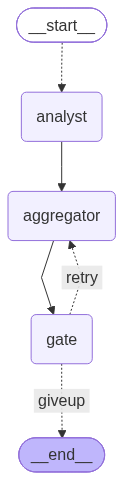

In [95]:
g = StateGraph(TeamState)
g.add_node("analyst", analyst_node)
g.add_node("aggregator", aggregator_node)
g.add_node("gate", gate_node)
g.add_conditional_edges(START, dispatch, ["analyst"])  # fan-out (Day 4)
# TODO: fan-in — 분석가들이 통합자(aggregator)로 모이는 엣지를 추가하세요
g.add_edge("analyst", "aggregator")

g.add_edge("aggregator", "gate")
# TODO: gate 노드에 조건 엣지를 추가하세요 — route_verdict 판정이 pass·giveup이면 END, retry면 aggregator로 되돌아간다
g.add_conditional_edges(
    "gate",
    route_verdict,
    {
        "pass": END,
        "giveup": END,
        "retry": "aggregator",
    },
)
research_team = g.compile()
research_team

In [97]:
def run_capstone(source):
    start_state = {"source": source, "analyses": [], "attempts": 0, "best_score": -1,
                   "best_clean": False, "rounds": [], "feedback": ""}
    result = research_team.invoke(start_state)
    print("[라운드 로그]")
    for line in result["rounds"]:
        print(" ", line)
    print(f"[판정] {result['verdict']} / 채택본 점수 {result['best_score']}/15")
    print("[제목]", result["best_report"]["title"])
    print("[본문]", result["best_report"]["body"])
    print("[마지막 개선 지시]", result["feedback"])  # 점수가 안 오르면 무엇을 요구받았는지 본다
    return result


result = run_capstone(SOURCE)

[라운드 로그]
  1차: 스타일 위반 0건 / 루브릭 9/15 → retry
  2차: 스타일 위반 0건 / 루브릭 9/15 → retry
  3차: 스타일 위반 0건 / 루브릭 15/15 → pass
[판정] pass / 채택본 점수 15/15
[제목] 달빛 도서관 투자자 보고서
[본문] 달빛 도서관은 서울 마포구에 위치한 무인 야간 도서관으로, 밤 10시부터 새벽 2시까지 운영됩니다. 총 48석의 좌석을 보유하고 있으며, 월 구독제로 운영되어 구독료는 월 19,900원입니다. 고객 서비스는 안내 로봇 '루나'가 담당하며, 책 추천과 반납을 지원합니다. 조용한 환경을 위해 통화와 취식은 금지되어 있습니다. 회원의 62%는 20~30대 직장인으로 구성되어 있으며, 2026년 12월에는 부산에 2호점이 개점할 예정입니다.
[마지막 개선 지시] 
- 모든 주장이 SOURCE에 의해 뒷받침되며, 명확하고 완전하게 전달되었습니다.


**관찰 포인트**: 몇 라운드 만에 끝났는가? 재무 분석가의 계산이 보고서에 들어갔는가, 걸러졌는가?

## Part 3-확장. Day 4에서 틀렸던 자료로 시험

Day 4 3-3에서 수영 클럽 보고서는 강습료를 두고 원문과 어긋난 충돌을 만들었다 (예: "**추가 강습료**가 부담", "강습료 포함의 **불확실성**" — 어떤 문장이 나올지는 실행마다 다르다). 원문은 "강습료가 **포함**"으로 확정된 사실이다.
같은 자료를 캡스톤 팀에 넣는다. 수영 클럽 자료에 맞게 필수 수치를 바꾼다 (회비·회원 수).

In [98]:
SOURCE2 = """[내부 소개 자료] 새벽 수영 클럽
새벽 수영 클럽은 평일 오전 5시 30분부터 7시까지 운영하는 직장인 수영 모임이다.
장소는 성수동의 실내 수영장이며, 레인 3개를 통째로 빌려 쓴다.
월 회비는 89,000원이고, 강습료가 포함되어 있다.
초급반·중급반·자유수영반 세 반으로 나뉜다.
수료 기준을 통과하면 한강 야외 수영 행사에 참가할 수 있다.
현재 회원은 74명이며 대기자가 30명이 넘는다."""

# TODO: 게이트의 필수 수치 REQUIRED를 수영 클럽 자료에 맞게 바꾸세요 — 회비와 회원 수 두 개 (원문 표기 그대로)
REQUIRED = ["89,000원", "74명"]

result2 = run_capstone(SOURCE2)
print("\n['강습료' 언급 문장]")
for sentence in result2["best_report"]["body"].split("."):
    if "강습" in sentence:
        print("-", sentence.strip())

[라운드 로그]
  1차: 스타일 위반 0건 / 루브릭 9/15 → retry
  2차: 스타일 위반 0건 / 루브릭 15/15 → pass
[판정] pass / 채택본 점수 15/15
[제목] 새벽 수영 클럽 투자자 보고서
[본문] 새벽 수영 클럽은 평일 오전 5시 30분부터 7시까지 운영되는 직장인 수영 모임으로, 성수동의 실내 수영장에서 레인 3개를 전세로 빌려 사용합니다. 현재 회원 수는 74명이며, 대기자는 30명 이상으로 클럽의 인기가 높습니다. 월 회비는 89,000원으로 강습료가 포함되어 있으며, 초급반, 중급반, 자유수영반으로 나뉘어 다양한 수준의 회원들에게 맞춤형 강습을 제공합니다. 수료 기준을 통과한 회원은 한강 야외 수영 행사에 참가할 수 있는 기회를 제공받아 추가적인 동기부여를 받을 수 있습니다.
[마지막 개선 지시] 
- 모든 주장이 SOURCE에 의해 뒷받침되며, 내용이 명확하게 전달되었습니다.

['강습료' 언급 문장]
- 월 회비는 89,000원으로 강습료가 포함되어 있으며, 초급반, 중급반, 자유수영반으로 나뉘어 다양한 수준의 회원들에게 맞춤형 강습을 제공합니다


**관찰 포인트**: 이번 보고서는 강습료를 원문대로("포함") 썼는가? 틀렸다면 게이트(검증자)가 잡았는가?

## 확인 문제

1. 통과 판정 `passed`를 LLM에게 묻지 않고 코드로 계산하는 이유는?
2. 2과목 Day 16 Self-Reflection과 오늘 루프의 가장 큰 차이는?
3. "모르고 다시"와 "알고 다시"의 결과 차이가 알려 주는 것은?
4. 채점이 재현 가능해지는 조건 세 가지는?
5. 검증자 시험(Part 2-확장)을 하는 이유는?
6. 캡스톤에서 게이트 미달 시 분석부터 다시 하지 않고 통합자로만 되돌아가는 이유는?

## 정리·회고 — M1 총정리

| Day | 질문 | 답 |
| --- | --- | --- |
| 1 | 구조가 품질을 올리나? | 작성자 → 검사기 → 수정자, 판정은 코드로 |
| 2 | 역할을 어떻게 나누고 넘기나? | 역할 정의서 + 데이터 계약 + 인계서 |
| 3 | 다음 일은 누가 정하나? | Supervisor(매 단계) · Router(입구 1회) |
| 4 | 독립인 일을 왜 줄 세우나? | 병렬 fan-out/fan-in + 통합자(충돌 명시) + MCP 자료실 |
| 5 | 품질은 누가 보장하나? | 게이트(코드 + 루브릭) + 피드백 루프 + 검증자 시험 |

오늘 배운 것을 3줄로 정리해 본다.

1. 게이트가 1차에 통과해도 게이트를 없애면 안 되는 이유는?
2. M1 리서치 팀에서 "판정은 코드로" 원칙이 쓰인 곳을 세 군데 이상 말해 본다.
3. 검증자를 믿기 전에 무엇을 확인해야 하는가?

```powershell
git add .
git commit -m "Day5: 품질 게이트 + 피드백 루프, M1 리서치 팀 완성"
```

**다음 주 예고 (M2, Day 6~11)**: 지금까지 만든 것은 내 노트북에서만 돈다. Day 6부터는 Day 1의 상품 소개문 서비스(작성자 + 규칙 검사기)를 FastAPI로 감싸고 Docker에 담아 **서비스로 내보내는** 운영 체계를 익힌다. 그 체계는 Day 16에 오늘의 리서치 팀에 입힌다.